# Breast Cancer (BCSC) - Análise

Colunas do arquivo pré-processado (`breast_cancer_screening_bcsc_processed.csv`):

| # | Coluna | O que é | Valores no arquivo processado |
|---|---|---|---|
| 0 | **Age_At_The_Time_Of_Mammography** | Idade da mulher no dia da mamografia | 60 a 89 (anos) |
| 1 | **Radiologists_Assessment** | Conclusão do radiologista ao olhar o exame (escala BI-RADS) | 1 = Negative (nada encontrado), 2 = Benign findings (achado benigno), 3 = Probably benign (provavelmente benigno), 4 = Needs additional imaging (precisa de mais exames), 5 = Suspicious abnormality (suspeito), 6 = Highly suggestive of malignancy (muito provável que seja câncer) |
| 2 | **Is_Binary_Indicator_Of_Cancer_Diagnosis** | **Alvo:** se ela recebeu diagnóstico de câncer de mama em até 1 ano depois do exame | 0 = não, 1 = sim (só 0,65% dos exames) |
| 3 | **Comparison_Mammogram_From_Mammography** | Se havia uma mamografia antiga para o radiologista comparar com a atual | 0 = não, 1 = sim |
| 4 | **Patients_BI_RADS_Breast_Density** | Densidade da mama, ou seja, quanto tecido glandular ela tem em relação a gordura. Mama densa dificulta ver tumores e tem risco um pouco maior | 1 = quase toda gordura, 2 = áreas dispersas de tecido denso, 3 = heterogeneamente densa, 4 = extremamente densa |
| 5 | **Family_History_Of_Breast_Cancer** | Se a mãe, uma irmã ou uma filha teve câncer de mama | 0 = não, 1 = sim |
| 6 | **Current_Use_Of_Hormone_Therapy** | Se ela usava terapia de reposição hormonal na época do exame | 0 = não, 1 = sim |
| 7 | **Binary_Indicator** | Se ela já tinha feito alguma mamografia antes desta. O nome da coluna no arquivo original é genérico mesmo | 0 = não, 1 = sim |
| 8 | **History_Of_Breast_Biopsy** | Se ela já tinha feito biópsia de mama antes | 0 = não, 1 = sim |
| 9 | **Is_Film_Or_Digital_Mammogram** | Tipo de aparelho usado no exame | 0 = filme, 1 = digital |
| 10 | **Patients_Study_ID** | Código que identifica a mulher. **Não é uma feature**: serve só para saber quais exames são da mesma pessoa (algumas fizeram mais de um) | número de identificação |


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../dataset/breast_cancer_screening_bcsc_processed.csv")

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 39998 entries, 0 to 39997
Data columns (total 11 columns):
 #   Column                                   Non-Null Count  Dtype
---  ------                                   --------------  -----
 0   Age_At_The_Time_Of_Mammography           39998 non-null  int64
 1   Radiologists_Assessment                  39998 non-null  int64
 2   Is_Binary_Indicator_Of_Cancer_Diagnosis  39998 non-null  int64
 3   Comparison_Mammogram_From_Mammography    39998 non-null  int64
 4   Patients_BI_RADS_Breast_Density          39998 non-null  int64
 5   Family_History_Of_Breast_Cancer          39998 non-null  int64
 6   Current_Use_Of_Hormone_Therapy           39998 non-null  int64
 7   Binary_Indicator                         39998 non-null  int64
 8   History_Of_Breast_Biopsy                 39998 non-null  int64
 9   Is_Film_Or_Digital_Mammogram             39998 non-null  int64
 10  Patients_Study_ID                        39998 non-null  int64
dtypes: int64(11)


In [ ]:
# Visão geral da amostra
# Cada linha representa um exame; uma paciente pode ter mais de um exame.
exames_por_paciente = df["Patients_Study_ID"].value_counts()

total_exames = len(df)
total_pacientes = df["Patients_Study_ID"].nunique()
pacientes_com_exames_repetidos = (exames_por_paciente > 1).sum()
exames_adicionais = total_exames - total_pacientes

visao_geral_amostra = pd.DataFrame({
    "Indicador": [
        "Total de exames",
        "Pacientes distintas",
        "Pacientes com mais de um exame",
        "Exames além do primeiro de cada paciente",
    ],
    "Quantidade": [
        total_exames,
        total_pacientes,
        pacientes_com_exames_repetidos,
        exames_adicionais,
    ],
})

visao_geral_amostra


Indicador,Quantidade
Total de exames,39998
Pacientes distintas,36714
Pacientes com mais de um exame,3133
Exames além do primeiro de cada paciente,3284


In [ ]:
# Valores ausentes na base bruta e tratamento aplicado
# df_bruto é separado do df processado usado nas demais análises.
df_bruto = pd.read_csv("../dataset/breast_cancer_screening_bcsc.csv")

ausencias = df_bruto.isna().sum()
ausencias = ausencias[ausencias > 0].sort_values(ascending=False)

nomes_colunas_ausencias = {
    "Body_Mass_Index": "IMC",
    "Comparison_Mammogram_From_Mammography": "Exame anterior disponível",
    "Current_Use_Of_Hormone_Therapy": "Terapia hormonal",
    "History_Of_Breast_Biopsy": "Biópsia anterior",
    "Binary_Indicator": "Mamografia prévia",
    "Family_History_Of_Breast_Cancer": "Histórico familiar",
}

tratamentos_ausencias = {
    "Body_Mass_Index": "Coluna removida",
    "Comparison_Mammogram_From_Mammography": 'Preenchido com "Sim" (moda)',
    "Current_Use_Of_Hormone_Therapy": 'Preenchido com "Não" (moda)',
    "History_Of_Breast_Biopsy": 'Preenchido com "Não" (moda)',
    "Binary_Indicator": 'Preenchido com "Sim" (moda)',
    "Family_History_Of_Breast_Cancer": 'Preenchido com "Não" (moda)',
}

resumo_ausencias = pd.DataFrame({
    "Coluna": ausencias.index.map(nomes_colunas_ausencias),
    "Quantidade ausente": ausencias.to_numpy(),
    "Percentual ausente (%)": (ausencias / len(df_bruto) * 100).round(2).to_numpy(),
    "Tratamento aplicado": ausencias.index.map(tratamentos_ausencias),
})

resumo_ausencias


Coluna,Quantidade ausente,Percentual ausente (%),Tratamento aplicado
IMC,23208,58.02,Coluna removida
Exame anterior disponível,4680,11.70,"Preenchido com ""Sim"" (moda)"
Terapia hormonal,1772,4.43,"Preenchido com ""Não"" (moda)"
Biópsia anterior,815,2.04,"Preenchido com ""Não"" (moda)"
Mamografia prévia,578,1.45,"Preenchido com ""Sim"" (moda)"
Histórico familiar,228,0.57,"Preenchido com ""Não"" (moda)"


In [3]:
df.loc[df['Age_At_The_Time_Of_Mammography'] > 80, ['Age_At_The_Time_Of_Mammography', 'Is_Binary_Indicator_Of_Cancer_Diagnosis']]

,Age_At_The_Time_Of_Mammography,Is_Binary_Indicator_Of_Cancer_Diagnosis
37,81,0
42,81,0
47,83,0
48,85,0
50,82,0
...,...,...
39929,83,0
39930,84,0
39939,86,0
39942,83,0


In [4]:
df['Age_At_The_Time_Of_Mammography'].describe()

count    39998.000000
mean        69.555703
std          7.202581
min         60.000000
25%         63.000000
50%         68.000000
75%         75.000000
max         89.000000
Name: Age_At_The_Time_Of_Mammography, dtype: float64

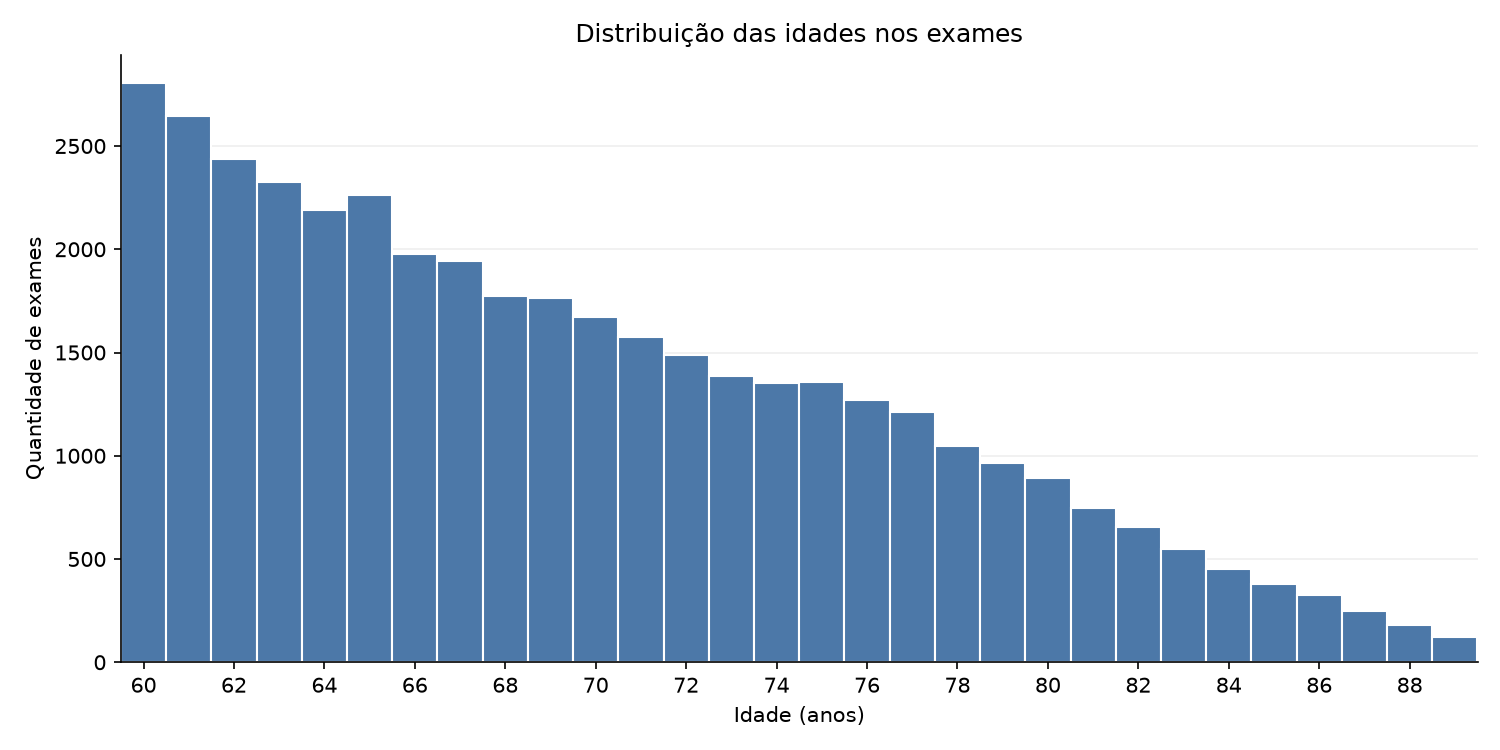

In [ ]:
# Histograma da idade
# Cada barra representa uma idade; a contagem é de exames, não de pacientes distintas.
fig, ax = plt.subplots(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Age_At_The_Time_Of_Mammography",
    discrete=True,
    stat="count",
    color="#4C78A8",
    edgecolor="white",
    alpha=1,
    ax=ax,
)

idade_minima = int(df["Age_At_The_Time_Of_Mammography"].min())
idade_maxima = int(df["Age_At_The_Time_Of_Mammography"].max())
ax.set_xticks(range(idade_minima, idade_maxima + 1, 2))
ax.set_xlim(idade_minima - 0.5, idade_maxima + 0.5)
ax.set_ylim(bottom=0)
ax.set_title("Distribuição das idades nos exames")
ax.set_xlabel("Idade (anos)")
ax.set_ylabel("Quantidade de exames")
ax.set_axisbelow(True)
ax.yaxis.grid(True, alpha=0.2)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()


In [ ]:
# Idade separada por diagnóstico
# As estatísticas são calculadas por exame; uma paciente pode aparecer mais de uma vez.
alvo = "Is_Binary_Indicator_Of_Cancer_Diagnosis"
coluna_idade = "Age_At_The_Time_Of_Mammography"

resumo_idade_por_diagnostico = (
    df.groupby(alvo)[coluna_idade]
    .describe()
    .rename(
        index={0: "Negativo", 1: "Positivo"},
        columns={
            "count": "Quantidade de exames",
            "mean": "Média (anos)",
            "std": "Desvio padrão (anos)",
            "min": "Mínimo (anos)",
            "25%": "1º quartil (anos)",
            "50%": "Mediana (anos)",
            "75%": "3º quartil (anos)",
            "max": "Máximo (anos)",
        },
    )
    .rename_axis("Diagnóstico em até 1 ano")
    .reset_index()
    .round(2)
)

resumo_idade_por_diagnostico["Quantidade de exames"] = (
    resumo_idade_por_diagnostico["Quantidade de exames"].astype(int)
)

resumo_idade_por_diagnostico


Diagnóstico em até 1 ano,Quantidade de exames,Média (anos),Desvio padrão (anos),Mínimo (anos),1º quartil (anos),Mediana (anos),3º quartil (anos),Máximo (anos)
Negativo,39739,69.55,7.20,60.0,63.0,68.0,75.0,89.0
Positivo,259,70.41,7.49,60.0,64.0,69.0,76.0,89.0


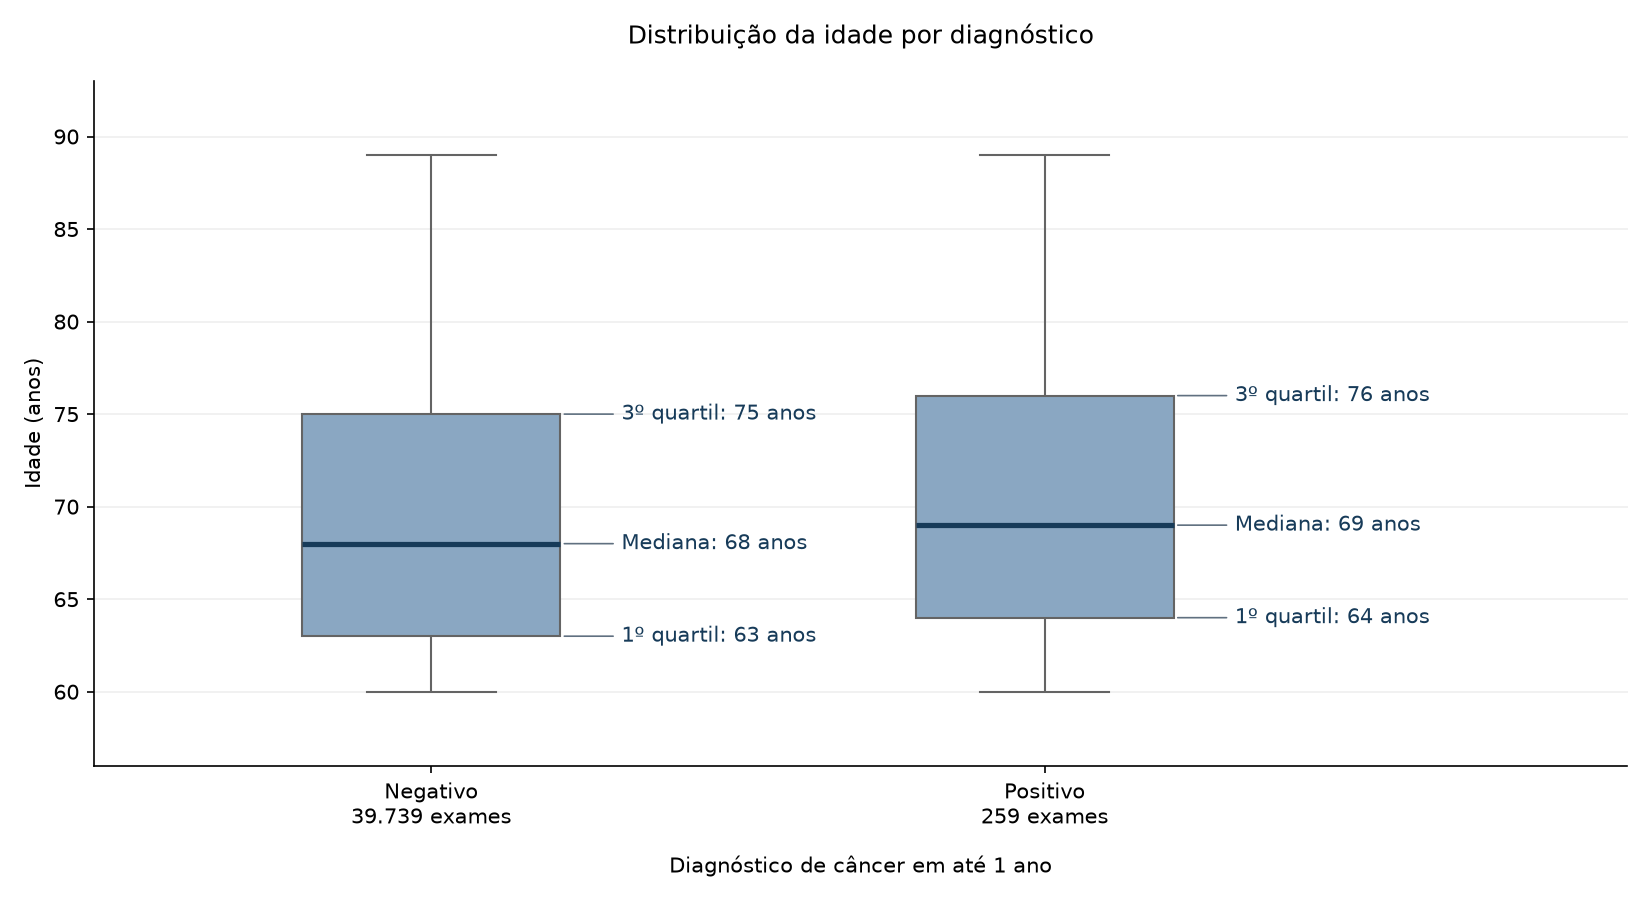

In [ ]:
# Boxplot da idade por diagnóstico
# As caixas resumem idades por exame; sua largura não representa o tamanho dos grupos.
# As hastes usam o limite de 1,5 vezes o intervalo interquartil; pontos indicam valores fora delas.
alvo = "Is_Binary_Indicator_Of_Cancer_Diagnosis"
coluna_idade = "Age_At_The_Time_Of_Mammography"
ordem_diagnostico = ["Negativo", "Positivo"]

dados_idade_diagnostico = df[[alvo, coluna_idade]].copy()
dados_idade_diagnostico["Diagnóstico"] = dados_idade_diagnostico[alvo].map(
    {0: "Negativo", 1: "Positivo"}
)

fig, ax = plt.subplots(figsize=(11, 6))
sns.boxplot(
    data=dados_idade_diagnostico,
    x="Diagnóstico",
    y=coluna_idade,
    order=ordem_diagnostico,
    color="#81A8CB",
    width=0.42,
    whis=1.5,
    showfliers=True,
    medianprops={"color": "#173B59", "linewidth": 2.5},
    ax=ax,
)

rotulos_grupos_idade = []
for posicao, diagnostico in enumerate(ordem_diagnostico):
    idades_grupo = dados_idade_diagnostico.loc[
        dados_idade_diagnostico["Diagnóstico"] == diagnostico, coluna_idade
    ]
    quantidade_formatada = f"{len(idades_grupo):,}".replace(",", ".")
    rotulos_grupos_idade.append(f"{diagnostico}\n{quantidade_formatada} exames")

    quartis_idade = idades_grupo.quantile([0.25, 0.5, 0.75])
    for nome, idade in zip(["1º quartil", "Mediana", "3º quartil"], quartis_idade):
        ax.annotate(
            f"{nome}: {idade:.0f} anos",
            xy=(posicao + 0.21, idade),
            xytext=(posicao + 0.31, idade),
            va="center",
            fontsize=10,
            color="#173B59",
            arrowprops={"arrowstyle": "-", "color": "#607080", "lw": 0.8},
        )

ax.set_xticks([0, 1], rotulos_grupos_idade)
ax.set_xlim(-0.55, 1.95)
ax.set_ylim(56, 93)
ax.set_yticks(range(60, 91, 5))
ax.set_title("Distribuição da idade por diagnóstico", pad=18)
ax.set_xlabel("Diagnóstico de câncer em até 1 ano", labelpad=12)
ax.set_ylabel("Idade (anos)")
ax.set_axisbelow(True)
ax.yaxis.grid(True, alpha=0.2)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()


In [ ]:
# Distribuição geral do diagnóstico em até um ano
alvo = "Is_Binary_Indicator_Of_Cancer_Diagnosis"
rotulos_diagnostico = {
    0: "Negativo",
    1: "Positivo",
}

quantidades_diagnostico = df[alvo].value_counts().reindex([0, 1], fill_value=0)

resumo_diagnostico = pd.DataFrame({
    "Diagnóstico em até 1 ano": [rotulos_diagnostico[codigo] for codigo in quantidades_diagnostico.index],
    "Quantidade de exames": quantidades_diagnostico.to_numpy(),
    "Percentual (%)": (quantidades_diagnostico / len(df) * 100).round(2).to_numpy(),
})

resumo_diagnostico


Diagnóstico em até 1 ano,Quantidade de exames,Percentual (%)
Negativo,39739,99.35
Positivo,259,0.65


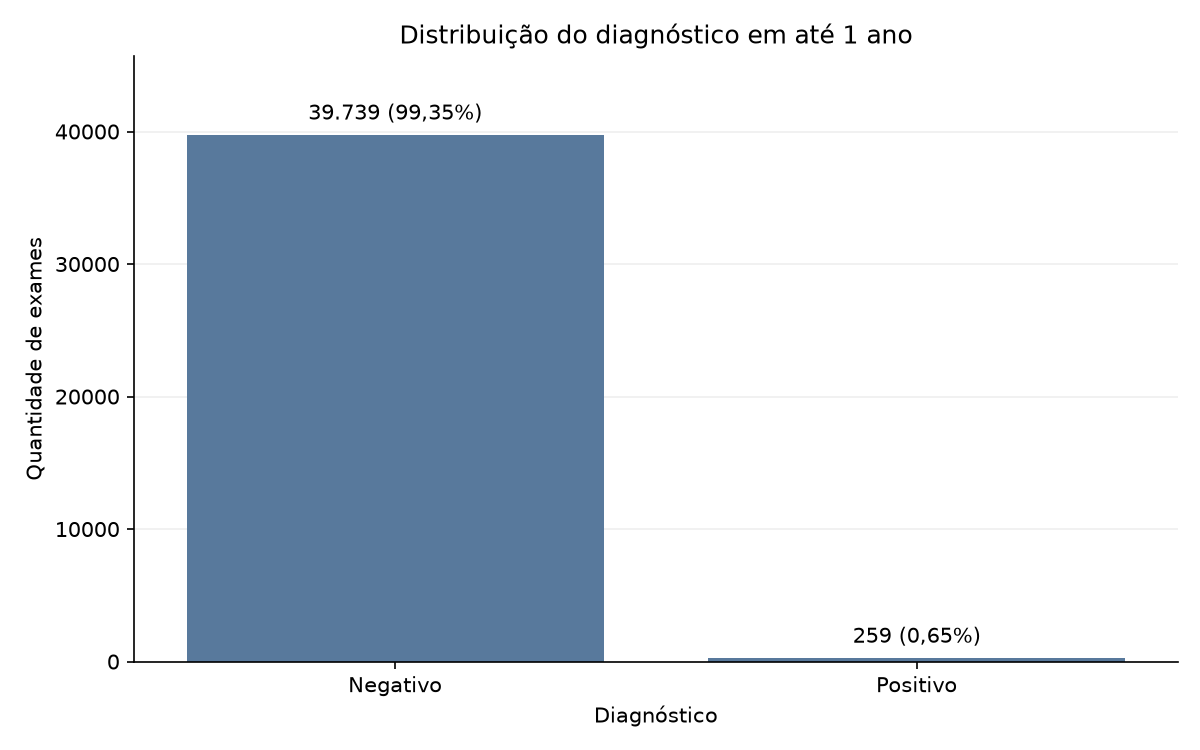

In [ ]:
# Gráfico da distribuição geral do diagnóstico
fig, ax = plt.subplots(figsize=(8, 5))

sns.barplot(
    data=resumo_diagnostico,
    x="Diagnóstico em até 1 ano",
    y="Quantidade de exames",
    order=resumo_diagnostico["Diagnóstico em até 1 ano"].tolist(),
    color="#4C78A8",
    errorbar=None,
    ax=ax,
)

rotulos_diagnostico_grafico = []
for quantidade, percentual in zip(
    resumo_diagnostico["Quantidade de exames"],
    resumo_diagnostico["Percentual (%)"],
):
    quantidade_formatada = f"{quantidade:,}".replace(",", ".")
    percentual_formatado = f"{percentual:.2f}".replace(".", ",")
    rotulos_diagnostico_grafico.append(
        f"{quantidade_formatada} ({percentual_formatado}%)"
    )

ax.bar_label(ax.containers[0], labels=rotulos_diagnostico_grafico, padding=5)
ax.set_title("Distribuição do diagnóstico em até 1 ano")
ax.set_xlabel("Diagnóstico")
ax.set_ylabel("Quantidade de exames")
ax.set_ylim(0, resumo_diagnostico["Quantidade de exames"].max() * 1.15)
ax.set_axisbelow(True)
ax.yaxis.grid(True, alpha=0.2)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()


In [6]:
# 60 anos
mais_60 = df.loc[df['Age_At_The_Time_Of_Mammography'] <= 70, ['Age_At_The_Time_Of_Mammography', 'Is_Binary_Indicator_Of_Cancer_Diagnosis']]

mais_60['Is_Binary_Indicator_Of_Cancer_Diagnosis'].value_counts(normalize=True)


Is_Binary_Indicator_Of_Cancer_Diagnosis
0    0.993904
1    0.006096
Name: proportion, dtype: float64

In [7]:
# 70 anos
mais_70 = df.loc[(df['Age_At_The_Time_Of_Mammography'] > 70) & (df['Age_At_The_Time_Of_Mammography'] <= 80), ['Age_At_The_Time_Of_Mammography', 'Is_Binary_Indicator_Of_Cancer_Diagnosis']]

mais_70['Is_Binary_Indicator_Of_Cancer_Diagnosis'].value_counts(normalize=True)

Is_Binary_Indicator_Of_Cancer_Diagnosis
0    0.993306
1    0.006694
Name: proportion, dtype: float64

In [8]:
# 80 anos
mais_80 = df.loc[df['Age_At_The_Time_Of_Mammography'] > 80, ['Age_At_The_Time_Of_Mammography', 'Is_Binary_Indicator_Of_Cancer_Diagnosis']]

mais_80['Is_Binary_Indicator_Of_Cancer_Diagnosis'].value_counts(normalize=True)

Is_Binary_Indicator_Of_Cancer_Diagnosis
0    0.991808
1    0.008192
Name: proportion, dtype: float64

In [ ]:
alvo = "Is_Binary_Indicator_Of_Cancer_Diagnosis"

faixas = {
    "60–70 anos": mais_60,
    "71–80 anos": mais_70,
    "81–89 anos": mais_80,
}

linhas = []

for faixa, exames in faixas.items():
    total = len(exames)
    negativos = (exames[alvo] == 0).sum()
    positivos = (exames[alvo] == 1).sum()

    linhas.append({
        "Faixa etária": faixa,
        "Total de exames": total,
        "Participação na amostra (%)": total / len(df) * 100,
        "Negativos": negativos,
        "Negativos (%)": negativos / total * 100,
        "Positivos": positivos,
        "Positivos (%)": positivos / total * 100,
    })

resumo_idade_diagnostico = pd.DataFrame(linhas).round(2)
resumo_idade_diagnostico

Faixa etária,Total de exames,Participação na amostra (%),Negativos,Negativos (%),Positivos,Positivos (%)
60–70 anos,23787,59.47,23642,99.39,145,0.61
71–80 anos,12549,31.37,12465,99.33,84,0.67
81–89 anos,3662,9.16,3632,99.18,30,0.82


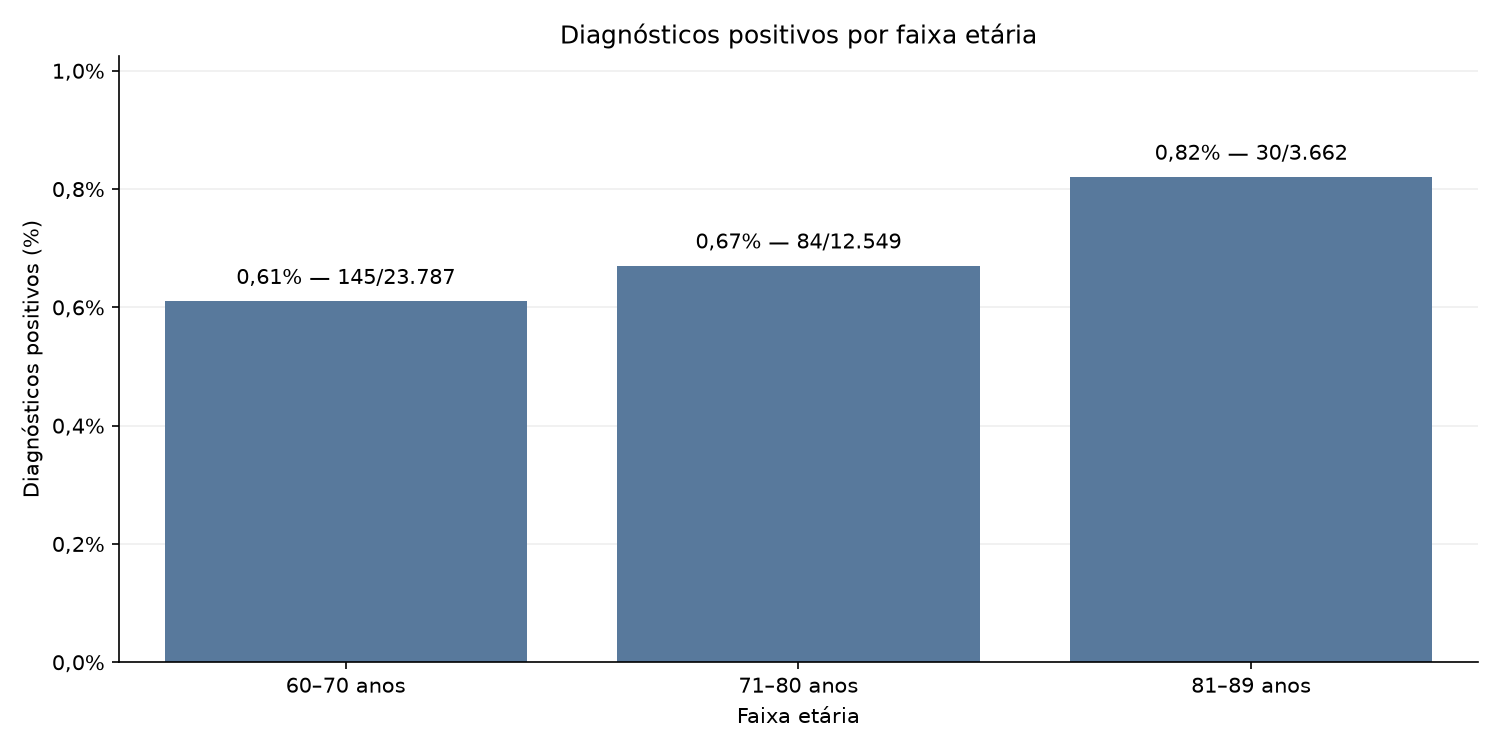

In [ ]:
# Percentual de diagnósticos positivos por faixa etária
from matplotlib.ticker import FuncFormatter

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(
    data=resumo_idade_diagnostico,
    x="Faixa etária",
    y="Positivos (%)",
    order=resumo_idade_diagnostico["Faixa etária"].tolist(),
    color="#4C78A8",
    errorbar=None,
    ax=ax,
)

rotulos_positivos_idade = []
for percentual, positivos, total in zip(
    resumo_idade_diagnostico["Positivos (%)"],
    resumo_idade_diagnostico["Positivos"],
    resumo_idade_diagnostico["Total de exames"],
):
    percentual_formatado = f"{percentual:.2f}".replace(".", ",")
    positivos_formatados = f"{positivos:,}".replace(",", ".")
    total_formatado = f"{total:,}".replace(",", ".")
    rotulos_positivos_idade.append(
        f"{percentual_formatado}% — {positivos_formatados}/{total_formatado}"
    )

ax.bar_label(ax.containers[0], labels=rotulos_positivos_idade, padding=6)
ax.set_title("Diagnósticos positivos por faixa etária")
ax.set_xlabel("Faixa etária")
ax.set_ylabel("Diagnósticos positivos (%)")
ax.set_ylim(0, resumo_idade_diagnostico["Positivos (%)"].max() * 1.25)
# A tabela já contém percentuais: 0,61 representa 0,61%, não 61%.
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda valor, posicao: f"{valor:.1f}%".replace(".", ","))
)
ax.set_axisbelow(True)
ax.yaxis.grid(True, alpha=0.2)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()


In [ ]:
# Densidade mamária x diagnóstico
alvo = "Is_Binary_Indicator_Of_Cancer_Diagnosis"
coluna_densidade = "Patients_BI_RADS_Breast_Density"

categorias_densidade = {
    1: "Quase inteiramente gordurosa",
    2: "Densidades fibroglandulares dispersas",
    3: "Heterogeneamente densa",
    4: "Extremamente densa",
}

linhas_densidade = []

for codigo, categoria in categorias_densidade.items():
    exames = df.loc[df[coluna_densidade] == codigo]
    total = len(exames)
    negativos = (exames[alvo] == 0).sum()
    positivos = (exames[alvo] == 1).sum()

    linhas_densidade.append({
        "Densidade mamária": categoria,
        "Total de exames": total,
        "Participação na amostra (%)": total / len(df) * 100,
        "Negativos": negativos,
        "Negativos (%)": negativos / total * 100,
        "Positivos": positivos,
        "Positivos (%)": positivos / total * 100,
    })

resumo_densidade_diagnostico = pd.DataFrame(linhas_densidade).round(2)
resumo_densidade_diagnostico


Densidade mamária,Total de exames,Participação na amostra (%),Negativos,Negativos (%),Positivos,Positivos (%)
Quase inteiramente gordurosa,5429,13.57,5402,99.50,27,0.50
Densidades fibroglandulares dispersas,21246,53.12,21129,99.45,117,0.55
Heterogeneamente densa,12028,30.07,11920,99.10,108,0.90
Extremamente densa,1295,3.24,1288,99.46,7,0.54


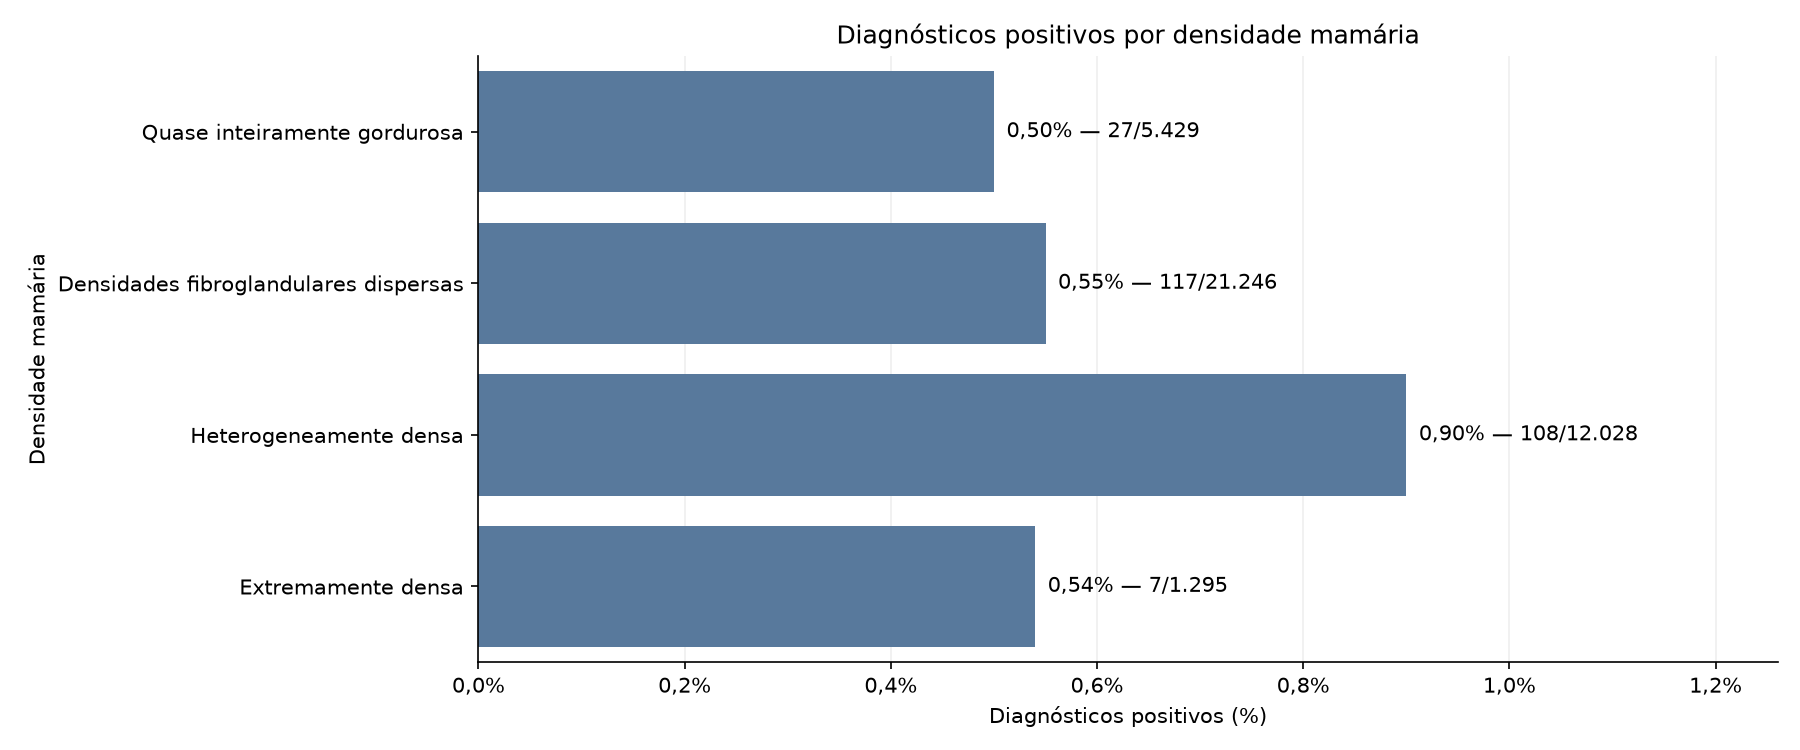

In [ ]:
# Percentual de diagnósticos positivos por densidade mamária
from matplotlib.ticker import FuncFormatter

fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(
    data=resumo_densidade_diagnostico,
    x="Positivos (%)",
    y="Densidade mamária",
    order=resumo_densidade_diagnostico["Densidade mamária"].tolist(),
    orient="h",
    color="#4C78A8",
    errorbar=None,
    ax=ax,
)

rotulos_positivos_densidade = []
for percentual, positivos, total in zip(
    resumo_densidade_diagnostico["Positivos (%)"],
    resumo_densidade_diagnostico["Positivos"],
    resumo_densidade_diagnostico["Total de exames"],
):
    percentual_formatado = f"{percentual:.2f}".replace(".", ",")
    positivos_formatados = f"{positivos:,}".replace(",", ".")
    total_formatado = f"{total:,}".replace(",", ".")
    rotulos_positivos_densidade.append(
        f"{percentual_formatado}% — {positivos_formatados}/{total_formatado}"
    )

ax.bar_label(ax.containers[0], labels=rotulos_positivos_densidade, padding=6)
ax.set_title("Diagnósticos positivos por densidade mamária")
ax.set_xlabel("Diagnósticos positivos (%)")
ax.set_ylabel("Densidade mamária")
ax.set_xlim(0, resumo_densidade_diagnostico["Positivos (%)"].max() * 1.4)
# Os valores já estão em percentual; a ordem das categorias segue a densidade.
ax.xaxis.set_major_formatter(
    FuncFormatter(lambda valor, posicao: f"{valor:.1f}%".replace(".", ","))
)
ax.set_axisbelow(True)
ax.xaxis.grid(True, alpha=0.2)
sns.despine(ax=ax)
fig.tight_layout()
plt.show()


In [ ]:
# Histórico familiar x diagnóstico
# No pré-processamento, 228 valores ausentes foram preenchidos com "Não".
alvo = "Is_Binary_Indicator_Of_Cancer_Diagnosis"
coluna_historico_familiar = "Family_History_Of_Breast_Cancer"
categorias_historico_familiar = {0: "Não", 1: "Sim"}

linhas_historico_familiar = []

for codigo, categoria in categorias_historico_familiar.items():
    exames = df.loc[df[coluna_historico_familiar] == codigo]
    total = len(exames)
    negativos = (exames[alvo] == 0).sum()
    positivos = (exames[alvo] == 1).sum()

    linhas_historico_familiar.append({
        "Histórico familiar": categoria,
        "Total de exames": total,
        "Participação na amostra (%)": total / len(df) * 100,
        "Negativos": negativos,
        "Negativos (%)": negativos / total * 100,
        "Positivos": positivos,
        "Positivos (%)": positivos / total * 100,
    })

resumo_historico_familiar = pd.DataFrame(linhas_historico_familiar).round(2)
resumo_historico_familiar


Histórico familiar,Total de exames,Participação na amostra (%),Negativos,Negativos (%),Positivos,Positivos (%)
Não,33255,83.14,33045,99.37,210,0.63
Sim,6743,16.86,6694,99.27,49,0.73


In [ ]:
# Biópsia anterior x diagnóstico
# Indica se a mulher já havia feito biópsia de mama, não o resultado da biópsia.
# No pré-processamento, 815 valores ausentes foram preenchidos com "Não".
alvo = "Is_Binary_Indicator_Of_Cancer_Diagnosis"
coluna_biopsia_anterior = "History_Of_Breast_Biopsy"
categorias_biopsia_anterior = {0: "Não", 1: "Sim"}

linhas_biopsia_anterior = []

for codigo, categoria in categorias_biopsia_anterior.items():
    exames = df.loc[df[coluna_biopsia_anterior] == codigo]
    total = len(exames)
    negativos = (exames[alvo] == 0).sum()
    positivos = (exames[alvo] == 1).sum()

    linhas_biopsia_anterior.append({
        "Biópsia anterior": categoria,
        "Total de exames": total,
        "Participação na amostra (%)": total / len(df) * 100,
        "Negativos": negativos,
        "Negativos (%)": negativos / total * 100,
        "Positivos": positivos,
        "Positivos (%)": positivos / total * 100,
    })

resumo_biopsia_anterior = pd.DataFrame(linhas_biopsia_anterior).round(2)
resumo_biopsia_anterior


Biópsia anterior,Total de exames,Participação na amostra (%),Negativos,Negativos (%),Positivos,Positivos (%)
Não,29548,73.87,29386,99.45,162,0.55
Sim,10450,26.13,10353,99.07,97,0.93


In [ ]:
# Terapia hormonal x diagnóstico
# No pré-processamento, 1.772 valores ausentes foram preenchidos com "Não".
alvo = "Is_Binary_Indicator_Of_Cancer_Diagnosis"
coluna_terapia_hormonal = "Current_Use_Of_Hormone_Therapy"
categorias_terapia_hormonal = {0: "Não", 1: "Sim"}

linhas_terapia_hormonal = []

for codigo, categoria in categorias_terapia_hormonal.items():
    exames = df.loc[df[coluna_terapia_hormonal] == codigo]
    total = len(exames)
    negativos = (exames[alvo] == 0).sum()
    positivos = (exames[alvo] == 1).sum()

    linhas_terapia_hormonal.append({
        "Terapia hormonal": categoria,
        "Total de exames": total,
        "Participação na amostra (%)": total / len(df) * 100,
        "Negativos": negativos,
        "Negativos (%)": negativos / total * 100,
        "Positivos": positivos,
        "Positivos (%)": positivos / total * 100,
    })

resumo_terapia_hormonal = pd.DataFrame(linhas_terapia_hormonal).round(2)
resumo_terapia_hormonal


Terapia hormonal,Total de exames,Participação na amostra (%),Negativos,Negativos (%),Positivos,Positivos (%)
Não,35749,89.38,35519,99.36,230,0.64
Sim,4249,10.62,4220,99.32,29,0.68


In [ ]:
# Filme x digital — diagnóstico
alvo = "Is_Binary_Indicator_Of_Cancer_Diagnosis"
coluna_tipo_mamografia = "Is_Film_Or_Digital_Mammogram"
categorias_tipo_mamografia = {0: "Filme", 1: "Digital"}

linhas_tipo_mamografia = []

for codigo, categoria in categorias_tipo_mamografia.items():
    exames = df.loc[df[coluna_tipo_mamografia] == codigo]
    total = len(exames)
    negativos = (exames[alvo] == 0).sum()
    positivos = (exames[alvo] == 1).sum()

    linhas_tipo_mamografia.append({
        "Tipo de mamografia": categoria,
        "Total de exames": total,
        "Participação na amostra (%)": total / len(df) * 100,
        "Negativos": negativos,
        "Negativos (%)": negativos / total * 100,
        "Positivos": positivos,
        "Positivos (%)": positivos / total * 100,
    })

resumo_tipo_mamografia = pd.DataFrame(linhas_tipo_mamografia).round(2)
resumo_tipo_mamografia


Tipo de mamografia,Total de exames,Participação na amostra (%),Negativos,Negativos (%),Positivos,Positivos (%)
Filme,19998,50.0,19861,99.31,137,0.69
Digital,20000,50.0,19878,99.39,122,0.61


In [ ]:
# Mamografia prévia x diagnóstico
# No pré-processamento, 578 valores ausentes foram preenchidos com "Sim".
alvo = "Is_Binary_Indicator_Of_Cancer_Diagnosis"
coluna_mamografia_previa = "Binary_Indicator"
categorias_mamografia_previa = {0: "Não", 1: "Sim"}

linhas_mamografia_previa = []

for codigo, categoria in categorias_mamografia_previa.items():
    exames = df.loc[df[coluna_mamografia_previa] == codigo]
    total = len(exames)
    negativos = (exames[alvo] == 0).sum()
    positivos = (exames[alvo] == 1).sum()

    linhas_mamografia_previa.append({
        "Mamografia prévia": categoria,
        "Total de exames": total,
        "Participação na amostra (%)": total / len(df) * 100,
        "Negativos": negativos,
        "Negativos (%)": negativos / total * 100,
        "Positivos": positivos,
        "Positivos (%)": positivos / total * 100,
    })

resumo_mamografia_previa = pd.DataFrame(linhas_mamografia_previa).round(2)
resumo_mamografia_previa


Mamografia prévia,Total de exames,Participação na amostra (%),Negativos,Negativos (%),Positivos,Positivos (%)
Não,296,0.74,292,98.65,4,1.35
Sim,39702,99.26,39447,99.36,255,0.64


In [ ]:
# Disponibilidade de exame anterior x diagnóstico
# Mamografia prévia indica se a mulher já fez o exame alguma vez.
# Esta variável indica se as imagens de um exame anterior estavam disponíveis
# para o radiologista comparar com as atuais. Ela pode ter feito uma mamografia
# em outra clínica, por exemplo, sem que as imagens estivessem disponíveis aqui.
# No pré-processamento, 4.680 valores ausentes foram preenchidos com "Sim".
alvo = "Is_Binary_Indicator_Of_Cancer_Diagnosis"
coluna_exame_anterior = "Comparison_Mammogram_From_Mammography"
categorias_exame_anterior = {0: "Não", 1: "Sim"}

linhas_exame_anterior = []

for codigo, categoria in categorias_exame_anterior.items():
    exames = df.loc[df[coluna_exame_anterior] == codigo]
    total = len(exames)
    negativos = (exames[alvo] == 0).sum()
    positivos = (exames[alvo] == 1).sum()

    linhas_exame_anterior.append({
        "Exame anterior disponível": categoria,
        "Total de exames": total,
        "Participação na amostra (%)": total / len(df) * 100,
        "Negativos": negativos,
        "Negativos (%)": negativos / total * 100,
        "Positivos": positivos,
        "Positivos (%)": positivos / total * 100,
    })

resumo_exame_anterior = pd.DataFrame(linhas_exame_anterior).round(2)
resumo_exame_anterior


Exame anterior disponível,Total de exames,Participação na amostra (%),Negativos,Negativos (%),Positivos,Positivos (%)
Não,1302,3.26,1286,98.77,16,1.23
Sim,38696,96.74,38453,99.37,243,0.63


In [ ]:
# Avaliação do radiologista x diagnóstico
# Os códigos 1–6 abaixo são internos ao arquivo processado, não os códigos BI-RADS originais.
# A avaliação do radiologista é diferente do diagnóstico de câncer em até um ano (alvo).
alvo = "Is_Binary_Indicator_Of_Cancer_Diagnosis"
coluna_avaliacao_radiologista = "Radiologists_Assessment"

categorias_avaliacao_radiologista = {
    1: "Negativo",
    2: "Achados benignos",
    3: "Provavelmente benigno",
    4: "Necessita de imagens adicionais",
    5: "Anormalidade suspeita",
    6: "Altamente sugestivo de malignidade",
}

linhas_avaliacao_radiologista = []

for codigo, categoria in categorias_avaliacao_radiologista.items():
    exames = df.loc[df[coluna_avaliacao_radiologista] == codigo]
    total = len(exames)
    negativos = (exames[alvo] == 0).sum()
    positivos = (exames[alvo] == 1).sum()

    linhas_avaliacao_radiologista.append({
        "Avaliação do radiologista": categoria,
        "Total de exames": total,
        "Participação na amostra (%)": total / len(df) * 100,
        "Negativos": negativos,
        "Negativos (%)": negativos / total * 100,
        "Positivos": positivos,
        "Positivos (%)": positivos / total * 100,
    })

resumo_avaliacao_radiologista = pd.DataFrame(linhas_avaliacao_radiologista).round(2)
resumo_avaliacao_radiologista


Avaliação do radiologista,Total de exames,Participação na amostra (%),Negativos,Negativos (%),Positivos,Positivos (%)
Negativo,26031,65.08,26011,99.92,20,0.08
Achados benignos,10717,26.79,10705,99.89,12,0.11
Provavelmente benigno,139,0.35,138,99.28,1,0.72
Necessita de imagens adicionais,3049,7.62,2851,93.51,198,6.49
Anormalidade suspeita,57,0.14,33,57.89,24,42.11
Altamente sugestivo de malignidade,5,0.01,1,20.00,4,80.00
